<div style="background:#102A43;color:#ffffff;border-radius:11px;padding:30px 28px 24px;border-top:7px solid #18B7AC;">
<div style="color:#67DED3;letter-spacing:2px;font-weight:700;font-size:12px;">INTRODUCTION TO MACHINE LEARNING · GAZA SKY GEEKS</div>
<div style="font-size:32px;font-weight:750;line-height:1.25;margin:12px 0 9px;">Lecture 04 · Visualizing Data<br>and Discovering Patterns</div>
<div style="font-size:15px;color:#DDEAF3;">Instructor: Diaeddin Rimawi &nbsp; | &nbsp; 27 October 2026</div>
<div style="font-size:17px;color:#ffffff;border-top:1px solid #466178;padding-top:16px;margin-top:18px;"><strong>Today's challenge:</strong> What if useful patterns are difficult to notice by looking at tables and numbers alone?</div>
</div>

**Our exploration journey**

**Ask a question → Choose a visualization → Create the plot → Interpret it → Ask a better question.**

Last time, we used Pandas to understand a dataset through rows, columns, filters, and summaries. Today, we will use **plots** to discover patterns that are hard to see in a table.

We will continue working with the same dataset: **Palmer Penguins**.

### What you will learn

By the end of this lecture, you should be able to:

1. Explain why data visualization is useful during **exploratory data analysis (EDA)**.
2. Create simple, clearly labeled plots with **Matplotlib**.
3. Use a **bar chart** to compare categories and a **histogram** to inspect numerical values.
4. Use a **box plot** to compare numerical measurements between groups.
5. Use a **scatter plot** to explore relationships between two numerical attributes.
6. Use **Seaborn** to show groups with less plotting code.
7. Choose a suitable plot and explain both its findings and its limitations.


<div style="background:#102A43;color:#ffffff;border-left:7px solid #18B7AC;padding:15px 20px;border-radius:7px;margin-top:26px;margin-bottom:10px;">
    <div style="color:#63DDD3;font-size:12px;letter-spacing:1.3px;font-weight:700;">01 · THE MOTIVATION</div>
    <div style="font-size:23px;font-weight:700;line-height:1.4;">From tables to visual questions</div>
    <div style="font-size:14px;color:#DDEAF3;margin-top:4px;">What can a picture show that a summary cannot?</div>
    </div>

In L03, we asked questions like: *How many penguins belong to each species?* and *What is the average body mass of each species?*

Those results are useful. They are also incomplete: an **average** does not show whether values are spread out, close together, or separated into groups.

Two groups may have nearly the same average, while the individual measurements still differ. To investigate, we need to see the **distribution**: how observations are spread across possible values.

This is part of **exploratory data analysis (EDA)**: examining data, looking for patterns, and asking better questions **before** building any machine learning model.

#### Our familiar dataset

The Palmer Penguins dataset describes individual penguins of three species, observed on three islands. It contains **344 rows** and **eight attributes**. A row describes one observation.

| Attribute | Meaning |
|---|---|
| `species`, `island`, `sex` | Categorical descriptions |
| `bill_length_mm`, `bill_depth_mm` | Bill measurements in millimeters |
| `flipper_length_mm` | Flipper length in millimeters |
| `body_mass_g` | Body mass in grams |
| `year` | Year of observation |

The CSV is included next to this notebook, inside the `data/` folder. We will not download data during class.

In [ ]:
# !python.exe -m pip install --upgrade pip
# !pip install seaborn


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

penguins = pd.read_csv("data/penguins.csv")
print("Dataset shape:", penguins.shape)
display(penguins.head())

The measurements are unchanged. We are only changing **how we look at them**.

Here is a numerical summary we already know how to compute.

In [ ]:
penguins.groupby("species")["body_mass_g"].mean().round(0)

**Notice:** the average body masses of **Adelie** and **Chinstrap** penguins are close to each other. But are their *individual body masses* also distributed in the same way?

A table of averages alone cannot answer that. We will return to this question when we learn histograms and box plots.


<div style="background:#102A43;color:#ffffff;border-left:7px solid #18B7AC;padding:15px 20px;border-radius:7px;margin-top:26px;margin-bottom:10px;">
    <div style="color:#63DDD3;font-size:12px;letter-spacing:1.3px;font-weight:700;">02 · FIRST PLOT</div>
    <div style="font-size:23px;font-weight:700;line-height:1.4;">Matplotlib: turning a question into a picture</div>
    <div style="font-size:14px;color:#DDEAF3;margin-top:4px;">One figure, one set of axes, one clear message</div>
    </div>

**Matplotlib** is a Python library for creating plots. We usually import its plotting functions with:

```python
import matplotlib.pyplot as plt
```

A **figure** is the complete picture. 

The **axes** are the area where data are drawn, including the horizontal (x) and vertical (y) directions. 

A **title** tells readers what question the plot answers; **axis labels** tell them what the values mean. 

A **plot** is the visual representation drawn inside the figure.

For beginners, this pattern is enough:

```python
fig, ax = plt.subplots()   # Create a figure and axes
# Add a plot to ax
# Add a title and axis labels
plt.show()                 # Display the figure
```

We will use it repeatedly so that the plot type is the main new idea.

#### Question 1: Which penguin species appears most frequently?

In L03, `value_counts()` answered this question with numbers. A **bar chart** makes the comparison easier to see. Each bar represents a **category**, and its height gives the number of observations in that category.

In [ ]:
species_counts = penguins["species"].value_counts()
species_counts

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4)) # 7 inch in width and 4 inch in height 
ax.bar(species_counts.index, species_counts.values, color="#158B94")
ax.set_title("How many penguins were observed in each species?")
ax.set_xlabel("Species")
ax.set_ylabel("Number of penguins")
ax.set_ylim(bottom=0)
plt.show()

**Read the plot:** Adelie is the most frequent species in this **dataset** (152 observations), followed by Gentoo (124) and Chinstrap (68).

The categories on the x-axis are **names**, not measurements. Their order does not represent a numerical distance. We start the count axis at **zero** so that the differences between bar heights are not exaggerated.

**What this does not show:** these counts describe the collected observations, not the total number of penguins living in Antarctica.

We have learned a useful pattern. Now, can you make the same kind of chart for another categorical attribute?

<div style="border-left:5px solid #18B7AC;background:#EEF8F7;padding:12px 16px;border-radius:5px;">
    <strong style="color:#102A43;">ACTIVITY 1 · Build a bar chart</strong><div style="color:#334E68;margin-top:5px;">How many penguins were recorded on each island? Use <code>value_counts()</code>, draw one bar for each island, and give the axes a title and labels. Compare your result with the species chart.</div></div>

In [ ]:
island_counts = penguins["island"].value_counts()

# Your turn: create a figure and axes; draw the bars.
# Add a title and axis labels. Use plt.show() to display your plot.

island_counts  # Useful counts while you work

<details>
<summary><strong>Suggested answer — click to expand after trying</strong></summary>

```python
island_counts = penguins["island"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(island_counts.index, island_counts.values, color="#158B94")
ax.set_title("How many penguins were recorded on each island?")
ax.set_xlabel("Island")
ax.set_ylabel("Number of penguins")
ax.set_ylim(bottom=0)
plt.show()
```

**Interpretation:** Biscoe has the most recorded penguins, followed by Dream and Torgersen. Remember that these are counts of **observations in this dataset**. They do not tell us which island has the largest total penguin population.

</details>

**Next question:** Counting species is useful, but penguins also have numerical measurements. A bar chart of species cannot tell us how their body masses vary.

What type of plot can show the overall shape of a numerical measurement?

<div style="background:#102A43;color:#ffffff;border-left:7px solid #18B7AC;padding:15px 20px;border-radius:7px;margin-top:26px;margin-bottom:10px;">
    <div style="color:#63DDD3;font-size:12px;letter-spacing:1.3px;font-weight:700;">03 · NUMERICAL VALUES</div>
    <div style="font-size:23px;font-weight:700;line-height:1.4;">Histograms: where do the measurements fall?</div>
    <div style="font-size:14px;color:#DDEAF3;margin-top:4px;">From categories to numerical intervals</div>
    </div>

#### Question 2: How are penguin body masses distributed?

A single average body mass hides the lighter and heavier penguins. We would like to know **which weight ranges are common** and whether most measurements are close together or widely spread.

A **histogram** divides a numerical range into intervals called **bins**. Each bar counts how many measurements fall inside one interval.

- **x-axis:** body mass ranges, measured in grams.
- **y-axis:** number of observed penguins in each range.
- **Neighboring bars:** adjacent intervals on one continuous numerical scale.

Unlike a bar chart of species, a histogram deals with **numerical intervals**, not separate category names.

Before plotting, remember the missing values from L03. `dropna()` gives us only the available body-mass measurements **for this plot**. We are not changing or cleaning the original DataFrame.

In [ ]:
body_mass = penguins["body_mass_g"].dropna()
print("All penguins:", len(penguins))
print("Body-mass values available for plotting:", len(body_mass))

**Predict:** Do you expect one large group of penguins around a single body mass, or several ranges with many observations? Run the plot to check.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(body_mass, bins=12, color="#158B94", edgecolor="white")
ax.set_title("How are penguin body masses distributed?")
ax.set_xlabel("Body mass (g)")
ax.set_ylabel("Number of penguins")
ax.set_ylim(bottom=0)
plt.show()

**Read the plot:** The recorded masses span a broad range, and some ranges contain more observations than others. The shape suggests that mixing all species together may hide important group differences.

We cannot tell **which species** a histogram bar represents yet. That leads to our next investigation.

#### Does the number of bins matter?

Yes. With **few bins**, we see a broad overview. With **many bins**, we see more detail, but the plot can look uneven. The observations do not change; only the *way we group them for display* changes.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharex=True, sharey=True)

axes[0].hist(body_mass, bins=5, color="#158B94", edgecolor="white")
axes[0].set_title("5 wide bins")
axes[1].hist(body_mass, bins=25, color="#158B94", edgecolor="white")
axes[1].set_title("25 narrow bins")

for ax in axes:
    ax.set_xlabel("Body mass (g)")
    ax.set_ylabel("Number of penguins")
    ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

**Compare carefully:** The x-axis uses the same units and range in both plots, but the bin widths differ. Each wide bin naturally includes more observations than a narrow bin. So compare the **visible shape**, not the raw height of one bar across these two plots.

There is no universally correct number of bins. Choosing a different bin count may reveal or hide details.

**Next question:** The histogram describes all penguins together. But we know that the three species have different average masses. Could the combined shape come from several groups with different measurements?

<div style="background:#102A43;color:#ffffff;border-left:7px solid #18B7AC;padding:15px 20px;border-radius:7px;margin-top:26px;margin-bottom:10px;">
    <div style="color:#63DDD3;font-size:12px;letter-spacing:1.3px;font-weight:700;">04 · COMPARING GROUPS</div>
    <div style="font-size:23px;font-weight:700;line-height:1.4;">Box plots: do species differ?</div>
    <div style="font-size:14px;color:#DDEAF3;margin-top:4px;">A compact summary of the middle, spread, and unusual points</div>
    </div>

#### Question 3: Do species have the same body-mass distribution?

To compare groups, we can put several **box plots** next to each other. Each box summarizes one group's numerical measurements.

Read the main parts intuitively:

- The **line inside the box** is the **median**: the middle value when measurements are ordered.
- The **box** contains the middle half of the observations. A taller box indicates a wider spread in that middle part.
- The **whiskers** extend beyond the box according to the plot's rule. Here, Matplotlib uses its usual **1.5 × IQR** convention; **IQR (Interquartile Range):** The difference between Q3 and Q1. It represents the width of the middle 50% of the data.
- Any **points beyond the whiskers** are *potentially unusual*, not automatically mistakes.

A box plot does **not** show every data value or the exact shape of the distribution. It gives us a compact comparison.

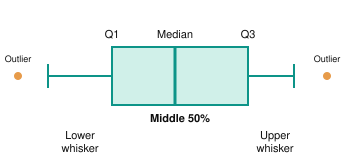

We can use the same Pandas selection skills from L03 to prepare one list of body masses for each species.

In [ ]:
species_order = ["Adelie", "Chinstrap", "Gentoo"]
colors = ["#158B94", "#DB9137", "#557AB5"]
masses_by_species = [
    penguins.loc[penguins["species"] == species, "body_mass_g"].dropna()
    for species in species_order
]

fig, ax = plt.subplots(figsize=(8, 4.5))
boxes = ax.boxplot(masses_by_species, tick_labels=species_order,
                   patch_artist=True)
for box, color in zip(boxes["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.75)
ax.set_title("How does body mass differ between species?")
ax.set_xlabel("Species")
ax.set_ylabel("Body mass (g)")
plt.show()

**Read the plot:** Gentoo penguins in these observations are generally heavier. Adelie and Chinstrap have similar middle values, but their ranges and spreads are not identical.

This adds information that the **mean alone** did not show. Notice that box plots can still overlap: species do not all have completely separate weight ranges.

**Important:** A point beyond a whisker is a reason to investigate, not a reason to delete the observation.

**Think together:** If our goal were to distinguish Gentoo penguins from the others, might body mass be useful? 

A box plot compares **one numerical attribute across categories**. But what if we want to explore a relationship between **two numerical attributes**? For that, we need a new kind of plot.

<div style="background:#102A43;color:#ffffff;border-left:7px solid #18B7AC;padding:15px 20px;border-radius:7px;margin-top:26px;margin-bottom:10px;">
    <div style="color:#63DDD3;font-size:12px;letter-spacing:1.3px;font-weight:700;">05 · RELATIONSHIPS</div>
    <div style="font-size:23px;font-weight:700;line-height:1.4;">Scatter plots: are two measurements connected?</div>
    <div style="font-size:14px;color:#DDEAF3;margin-top:4px;">One point is one penguin observation</div>
    </div>

#### Question 4: Do penguins with longer flippers tend to have greater body mass?

A **scatter plot** displays two numerical attributes together. Each point corresponds to one penguin for which **both measurements are present**.

- Its horizontal position is the penguin's **flipper length** in millimeters.
- Its vertical position is the penguin's **body mass** in grams.
- An upward pattern suggests a **positive relationship**: larger x-values often go with larger y-values.
- A downward pattern suggests a **negative relationship**; no clear trend suggests a weak or unclear relationship.

We may see points on top of each other when observations share similar measurements.

In [ ]:
flipper_mass = penguins[["flipper_length_mm", "body_mass_g"]].dropna()
print("Penguins with both measurements:", len(flipper_mass))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(flipper_mass["flipper_length_mm"],
           flipper_mass["body_mass_g"],
           color="#158B94", alpha=0.75)
ax.set_title("Are longer flippers associated with greater body mass?")
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Body mass (g)")
plt.show()

**Read the plot:** Across the observed penguins, longer flippers generally go together with greater body mass. The points form a broad upward pattern, rather than a perfect line.

**Do not confuse association with causation.** This plot does not prove that increasing flipper length *causes* body mass to increase. Species and other factors might help explain the pattern.

**A better question:** Are we observing one relationship for all penguins, or are different species forming separate groups? Before answering, try another two-measurement view yourself.

<div style="border-left:5px solid #18B7AC;background:#EEF8F7;padding:12px 16px;border-radius:5px;">
    <strong style="color:#102A43;">ACTIVITY 2 · Explore a different relationship</strong><div style="color:#334E68;margin-top:5px;">Create a scatter plot using <code>bill_length_mm</code> on the x-axis and <code>bill_depth_mm</code> on the y-axis. Describe any visible grouping or overlap.</div></div>

In [ ]:
bill_data = penguins[["bill_length_mm", "bill_depth_mm"]].dropna()

# Start with this plot. 
fig, ax = plt.subplots(figsize=(8, 4.5))
# Add scatter chart
ax.set_title("How are bill length and depth related?")
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
plt.show()

<details>
<summary><strong>Suggested answer — click to expand after trying</strong></summary>

```python
bill_data = penguins[["bill_length_mm", "bill_depth_mm"]].dropna()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(bill_data["bill_length_mm"], bill_data["bill_depth_mm"],
           color="#158B94", alpha=0.75)
ax.set_title("How are bill length and depth related?")
ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
plt.show()
```

**Interpretation:** The points are not arranged along one simple line. You can see areas with many observations and some separation, but the plot does not yet tell us *which species* contributes to each area. Coloring by species could answer that follow-up question.

</details>

<div style="background:#102A43;color:#ffffff;border-left:7px solid #18B7AC;padding:15px 20px;border-radius:7px;margin-top:26px;margin-bottom:10px;">
    <div style="color:#63DDD3;font-size:12px;letter-spacing:1.3px;font-weight:700;">06 · ADDING CONTEXT</div>
    <div style="font-size:23px;font-weight:700;line-height:1.4;">Seaborn: color reveals hidden groups</div>
    <div style="font-size:14px;color:#DDEAF3;margin-top:4px;">Same data, clearer group comparisons</div>
    </div>

#### Question 5: Does the flipper–mass relationship change when we show species?

Our first scatter plot used one color for all penguins. We now have a reason to use **Seaborn**.

**Seaborn** works with Matplotlib. It can read a Pandas DataFrame directly and use a categorical column to **color groups** automatically. The `hue` argument tells Seaborn which category controls the colors.

We will not learn a large plotting API. We will change **one important thing**: reveal each penguin's species.

In [ ]:
species_colors = {"Adelie": "#158B94",
                  "Chinstrap": "#DB9137",
                  "Gentoo": "#557AB5"}

fig, ax = plt.subplots(figsize=(8.5, 5))
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g",
                hue="species", hue_order=species_order,
                palette=species_colors, alpha=0.80, ax=ax)
ax.set_title("Flipper length and body mass, colored by species")
ax.set_xlabel("Flipper length (mm)")
ax.set_ylabel("Body mass (g)")
ax.legend(title="Species")
plt.show()

**Read the grouped plot:** Gentoo observations appear mainly toward the longer-flipper, higher-mass region. Adelie and Chinstrap appear mostly in shorter-flipper, lower-mass regions, with overlap.

This gives a more careful interpretation of the first scatter plot: the overall upward relationship is partly associated with **differences between species**. An upward tendency can also be seen within the species groups, but it is not equally strong or identical for every group.

**Key lesson:** A plot of all observations can hide meaningful subgroups. Color adds context; it does not add new measurements or prove a cause.

The colors must always have a **legend** so the reader knows which species each color represents.

#### Another use of Seaborn: compare group distributions

Our first histogram put all body masses together. We can now ask Seaborn to show a separate **outline** for each species. This provides another way to revisit the original question about Adelie and Chinstrap.

The lines represent histogram bars drawn as outlines, not fitted trends. Since the groups contain different numbers of observed penguins, compare their **typical ranges and overlap** carefully.

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=penguins, x="body_mass_g", hue="species",
             hue_order=species_order, palette=species_colors,
             bins=25, element="step", fill=False, ax=ax)
ax.set_title("Where do the body-mass ranges of species overlap?")
ax.set_xlabel("Body mass (g)")
ax.set_ylabel("Number of penguins")
plt.show()

**Read the plot:** The Gentoo distribution is shifted toward higher body masses, while Adelie and Chinstrap overlap more. Their similar averages are not the full story: the distributions give more context.

**Careful comparison:** Each species has a different number of recorded observations. A taller histogram outline may partly reflect **more observations**, not a stronger biological tendency. If we wanted to compare shapes independently of group size, we would need another display choice. That is a question for a later, more statistical treatment.

You have now used **Matplotlib** to build basic plots and **Seaborn** to add grouping more easily. The important skill is still choosing and interpreting the plot, not memorizing functions.

**Key takeaway**: Sometimes a pattern becomes easier to understand when we look at *meaningful groups* instead of treating all observations as one population.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5),
                         sharex=True, sharey=True)

# Left: All penguins together
sns.histplot(data=penguins, x="body_mass_g",
             bins=25, color="teal", ax=axes[0])

axes[0].set_title("Body mass: All penguins")
axes[0].set_xlabel("Body mass (g)")
axes[0].set_ylabel("Number of penguins")

# Right: Separate distributions by species
sns.histplot(data=penguins, x="body_mass_g", hue="species",
             hue_order=species_order, palette=species_colors,
             bins=25, element="step", fill=True, alpha=0.25, ax=axes[1])

axes[1].set_title("Body mass: By species")
axes[1].set_xlabel("Body mass (g)")
axes[1].set_ylabel("Number of penguins")

plt.tight_layout()
plt.show()

<div style="background:#102A43;color:#ffffff;border-left:7px solid #18B7AC;padding:15px 20px;border-radius:7px;margin-top:26px;margin-bottom:10px;">
    <div style="color:#63DDD3;font-size:12px;letter-spacing:1.3px;font-weight:700;">07 · GOOD JUDGMENT</div>
    <div style="font-size:23px;font-weight:700;line-height:1.4;">Choose the plot that answers your question</div>
    <div style="font-size:14px;color:#DDEAF3;margin-top:4px;">A good plot is a clear answer to a specific question</div>
    </div>

Start with the **question** and the **type of attributes**, not with a plotting command.

| Question | Data involved | Suitable plot |
|---|---|---|
| How many observations are in each species? | One categorical attribute | **Bar chart** |
| How are body masses spread across values? | One numerical attribute | **Histogram** |
| How do masses differ among species? | Numerical + categorical | **Box plot** |
| Do longer flippers go with greater body mass? | Two numerical attributes | **Scatter plot** |
| How does a quantity change over time? | Ordered time values + numerical values | **Line plot** |

A **line plot** connects values in their meaningful time order, such as daily temperature over a week. Connecting individual penguins with lines would be misleading: rows are **different penguins**, not successive measurements of the same animal. Here, we do not need a line plot.

#### Read responsibly

When presenting any plot, ask:

1. **What does each mark mean?** One penguin, a group count, or a numerical interval?
2. **Are the title, labels, units, and legend clear?** A mass axis without “g” is incomplete.
3. **What observations are missing?** Our body-mass plots used 342 values, not 344. Missing rows should not be hidden from the audience.
4. **Could the display exaggerate differences?** Counts in bar charts should start from zero; histogram bin choice matters; use scales carefully.
5. **Does the conclusion go beyond the evidence?** Plots may suggest relationships, but they do not prove causation or represent all penguins everywhere.

**Remember:** A plot can reveal a question worth investigating. It is not proof that our explanation is correct.

In [ ]:
print("Missing values in each attribute:")
print(penguins.isna().sum())
print()
print("Rows available for the flipper–mass scatter plot:",
      penguins[["flipper_length_mm", "body_mass_g"]].dropna().shape[0])

The count of observations used in a plot depends on its selected columns. We have **not** filled missing measurements, and we have not removed any rows from `penguins`. We only let the plot use available values. In L07 we will consider how to treat data quality problems more systematically.

<div style="border-left:5px solid #18B7AC;background:#EEF8F7;padding:12px 16px;border-radius:5px;">
    <strong style="color:#102A43;">ACTIVITY 3· Choose and interpret responsibly</strong><div style="color:#334E68;margin-top:5px;">For each question below, name a suitable plot and say what you would look for. </br><strong>(a)</strong> Which island has the most recorded penguins? </br><strong>(b)</strong> Do body-mass values vary widely? </br><strong>(c)</strong> Does bill length change with bill depth? </br><strong>(d)</strong> Are body-mass distributions different for Adelie and Gentoo? </br>Finally: can any of these plots prove a causal relationship?</div></div>

<details>
<summary><strong>Suggested answer — click to expand after trying</strong></summary>

```python
# No new code is required: this is an interpretation activity.
# (a) Bar chart     (b) Histogram
# (c) Scatter plot  (d) Box plot
```

**(a)** A bar chart compares category counts. **(b)** A histogram shows the spread and common ranges of one numerical attribute. **(c)** A scatter plot shows whether two measurements tend to vary together. **(d)** A box plot compares the middle and spread of masses between species. **None** of these plots alone proves a causal relationship. Each answers a different kind of question.

</details>

<div style="background:#102A43;color:#ffffff;border-left:7px solid #18B7AC;padding:15px 20px;border-radius:7px;margin-top:26px;margin-bottom:10px;">
    <div style="color:#63DDD3;font-size:12px;letter-spacing:1.3px;font-weight:700;">08 · BRING IT TOGETHER</div>
    <div style="font-size:23px;font-weight:700;line-height:1.4;">What did the penguin plots tell us?</div>
    <div style="font-size:14px;color:#DDEAF3;margin-top:4px;">Separate direct observations from possible explanations</div>
    </div>

We started with a table and ended with several connected discoveries.

| Our question | What we observed | A limitation or next question |
|---|---|---|
| Which species appears most often? | Adelie has the most observations (152). | Sampling counts are not population totals. |
| How are body masses distributed? | Values are spread across several ranges. | One histogram hides species membership; bin choice changes appearance. |
| Do species differ in body mass? | Gentoo is generally heavier in these data; Adelie and Chinstrap overlap. | Some measurements are missing and group sizes differ. |
| Do longer flippers go with greater mass? | There is a visible upward association. | The plot does not show causation. |
| Does species matter? | Color reveals partly separated groups and overlap. | More work is needed to explain *why* the patterns occur. |

**A useful distinction:**

- **Observed:** What the displayed data show (for example, Gentoo body masses are generally higher here).
- **Suggested:** A possible explanation (for example, species differences contribute to the overall flipper–mass pattern).
- **Not established:** A cause, a general rule for every penguin, or the success of a future prediction model.

This is the purpose of EDA: move from simple answers to **better questions**.


### 8.1 Visualizing Changes Across Years

Most plots we created today compared categories, distributions, or relationships between numerical attributes.

But sometimes our question involves **time**.

For example:

**How many penguins were recorded in each observation year?**

A line plot is useful for displaying how a quantity changes across ordered points, such as years.

Let's first use Pandas to count the observations for each year.


In [ ]:

observations_per_year = penguins.groupby("year").size()

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(observations_per_year.index,
        observations_per_year.values,
        marker="o", color="teal")

ax.set_title("How Many Penguins Were Recorded Each Year?")
ax.set_xlabel("Observation year")
ax.set_ylabel("Number of recorded penguins")
ax.set_xticks(observations_per_year.index)

plt.show()



<div style="background:#142D42;color:white;padding:14px 20px;border-left:5px solid #21B7AD;border-radius:5px;">
  <h2 style="margin:0;color:white;">9. Making Visualizations Ready to Share</h2>
</div>

So far, we have used plots to explore data and discover patterns.

But what if we want to include our findings in a report, presentation, or research paper?

A good visualization should not only be correct. It should also be **clear, readable, and easy to share**.

Let's see how we can control text appearance and save our plots.



### 9.1 Changing Fonts and Text Sizes

Matplotlib allows us to customize the appearance of text in our figures.

Two useful settings are:

- **Font family:** Controls the style of the text, such as `DejaVu Sans`, `DejaVu Serif`, or `monospace`.
- **Font size:** Controls how large the text appears.

We can specify these settings for individual elements or apply them to an entire figure.

Let's reuse our species comparison to see the difference.


In [ ]:

# Use a font style for this figure only
with plt.rc_context({"font.family": "DejaVu Serif", "font.size": 11}):

    fig, ax = plt.subplots(figsize=(8, 4.5))

    species_counts = penguins["species"].value_counts().reindex(species_order)

    ax.bar(species_counts.index, species_counts.values,
           color=[species_colors[s] for s in species_order])

    ax.set_title("Number of Penguins by Species", fontsize=16)
    ax.set_xlabel("Penguin species", fontsize=12)
    ax.set_ylabel("Number of penguins", fontsize=12)
    ax.tick_params(axis="both", labelsize=10)

    plt.show()



### 9.2 Saving Figures

When we create a useful visualization, we may want to export it as an image or document.

Matplotlib provides the `savefig()` function for this purpose.

Some common formats are:

| Format | Suitable for |
|---|---|
| PNG | Slides, websites, and general image sharing |
| PDF | Reports, scientific papers, and printing |
| SVG | Vector graphics that can be resized without losing quality |

For image formats such as PNG, we can also control the resolution using `dpi` (dots per inch).

For example, `dpi=300` is commonly used for high-resolution images.

Let's save the figure we just created.


In [ ]:

from pathlib import Path

# Create a folder for our exported figures
output_dir = Path("figures")
output_dir.mkdir(exist_ok=True)

# Save the figure in different formats
fig.savefig(output_dir / "penguins_by_species.png",
            dpi=300, bbox_inches="tight")

fig.savefig(output_dir / "penguins_by_species.pdf",
            bbox_inches="tight")

fig.savefig(output_dir / "penguins_by_species.svg",
            bbox_inches="tight")

print("Figures saved in:", output_dir)


**A few useful details:**

- The file extension determines the output format.
- `dpi=300` controls the resolution of the PNG image.
- `bbox_inches="tight"` reduces unnecessary whitespace around the figure.
- `fig.savefig()` saves the entire figure, including its title, labels, and legend.

**Good practice:** Save a figure before calling `plt.show()` when both operations are in the same code cell.

### Looking ahead — Lecture 05: Descriptive Statistics for Data Science

Today we *saw* distributions, group differences, and relationships. Next time we will learn to describe these patterns more precisely using statistics.

> **Our next question:** We can now see distributions and differences between groups. **How can we describe those patterns precisely using numbers?**


<div style="background:#142D42;color:white;padding:14px 20px;border-left:5px solid #21B7AD;border-radius:5px;">
  <h2 style="margin:0;color:white;">Assignment 02 — Exploring Penguin Bill Shapes</h2>
  <p style="margin:6px 0 0;color:#CBE7E5;">Week 2 | Pandas and Data Visualization</p>
</div>

### The Problem

Penguins have different physical characteristics, including bill length, bill depth, and body mass.

**Do penguins with relatively longer bills tend to have greater body mass? Does this relationship differ between species?**

### Your Investigation

**1. Create a new measurement**

Create a new attribute called `bill_shape_ratio`, calculated as:

$$
\text{Bill Shape Ratio} = \frac{\text{Bill Length (mm)}}{\text{Bill Depth (mm)}}
$$

This ratio describes the relative proportions of a penguin's bill. A higher value indicates a longer bill relative to its depth.

**2. Visualize the relationship**

Investigate the relationship between `bill_shape_ratio` and `body_mass_g`.

Use colors to distinguish the penguin species. 

>Make sure your visualization has a meaningful title, axis labels, and legend.

**3. Interpret your findings**

Based on your visualization, write a short conclusion:

- Is there a visible relationship between bill shape ratio and body mass?
- Does the relationship appear similar across species?
- Justify your conclusions using evidence from the plot.

### Submission

Submit one Jupyter notebook containing your analysis, visualization, and conclusions.


In [ ]:
# Assignment 02 — Your investigation



### Sources and acknowledgements

- **Palmer Penguins data:** Horst, A. M., Hill, A. P., and Gorman, K. B. (2020), *palmerpenguins: Palmer Archipelago (Antarctica) penguin data*. Dataset collected by Dr. Kristen Gorman and the Palmer Station LTER program. [Project and attribution](https://github.com/allisonhorst/palmerpenguins). The data are distributed under CC0. This notebook includes an offline CSV with the standard simplified eight-column schema.
- **Teaching inspirations:** Selected concepts were adapted from the teaching archive of **Prof. Antonio Liotta**.
- Further reading: [Matplotlib documentation](https://matplotlib.org/stable/), [Seaborn documentation](https://seaborn.pydata.org/), [Pandas documentation](https://pandas.pydata.org/docs/).

